# BrainScan AI — Brain Tumor Classification Using CNN

## Project objective

Develop a Convolutional Neural Network (CNN) to classify brain MRI images into four categories:

- Glioma tumor
- Meningioma tumor
- No tumor
- Pituitary tumor

The notebook covers dataset exploration, image preprocessing, model development, training, evaluation, and prediction.

**Important:** This is an educational AI project. Its predictions are not a substitute for professional medical diagnosis.

### Step 1: Import Libraries

Import the libraries needed for image processing, data visualization, CNN training, and evaluation.

In [8]:
import random
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)

TensorFlow: 2.22.0-rc0
OpenCV: 5.0.0


### Step 2: Dataset Path

Define the path to the dataset and verify that the folder exists.

In [11]:
DATA_DIR = Path("../data/brain_mri/Data")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR.resolve()}")

print("Dataset path:", DATA_DIR.resolve())
print("Model directory:", MODEL_DIR.resolve())
print("Classes:", sorted(folder.name for folder in DATA_DIR.iterdir() if folder.is_dir()))

Dataset path: /home/lahcen404/Desktop/YouCode-Y2/BrainScanAI/data/brain_mri/Data
Model directory: /home/lahcen404/Desktop/YouCode-Y2/BrainScanAI/models
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


### Dataset Structure

Inspect the extracted dataset to identify the class folders and verify that each class contains images.

In [10]:
print("Dataset exists:", DATA_DIR.exists())
print("Dataset path:", DATA_DIR.resolve())
print("Class folders:")

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        image_count = sum(1 for file in folder.iterdir() if file.is_file())
        print(f"{folder.name}: {image_count} files")

Dataset exists: True
Dataset path: /home/lahcen404/Desktop/YouCode-Y2/BrainScanAI/data/brain_mri/Data
Class folders:
glioma: 1621 files
meningioma: 1645 files
notumor: 2000 files
pituitary: 1757 files


### Verify Image Files

Count files with supported image extensions in each class. This helps identify the dataset size and potential class imbalance before loading images.

In [7]:
VALID_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}

class_counts = {}

for class_name in sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()):
    class_dir = DATA_DIR / class_name

    image_files = [
        file for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]

    class_counts[class_name] = len(image_files)

class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

display(class_counts_df)

print("Total supported image files:", sum(class_counts.values()))

,Class,Number of Images
0,glioma,1621
1,meningioma,1645
2,notumor,2000
3,pituitary,1757


Total supported image files: 7023


### Class Distribution

Visualize the number of images in each class to check whether the dataset is balanced.

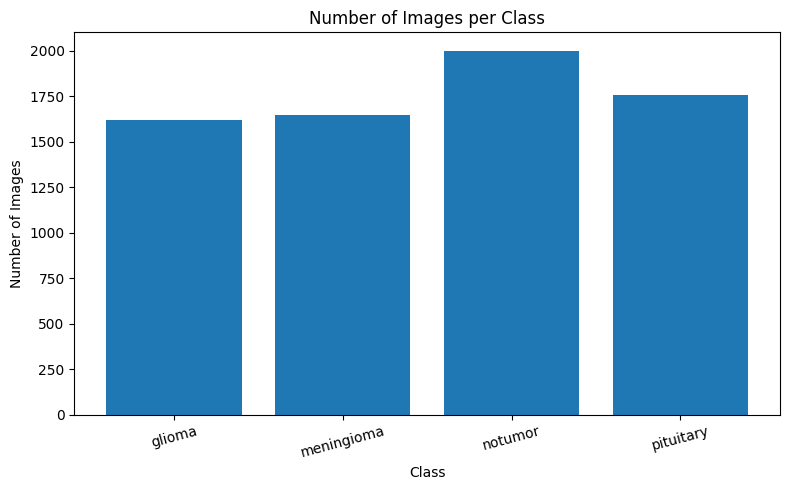

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Load and Resize Images

Read images from each class folder, resize them to 224 × 224 pixels, and store their corresponding labels. Keep images and labels aligned, and record files that fail to load.

In [ ]:
IMAGE_SIZE = (224, 224)
X = []
y = []
failed_images = []

for class_name in sorted(class_counts.keys()):
    class_dir = DATA_DIR / class_name

    for file in sorted(class_dir.iterdir()):
        if not file.is_file() or file.suffix.lower() not in VALID_EXTENSIONS:
            continue

        try:
            image = cv2.imread(str(file))

            if image is None:
                failed_images.append(str(file))
                continue

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, IMAGE_SIZE)

            X.append(image)
            y.append(class_name)

        except Exception as e:
            failed_images.append(str(file))
            print(f"Could not load {file.name}: {e}")

X = np.array(X, dtype=np.uint8)
y = np.array(y)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Failed images:", len(failed_images))
print("Unique labels:", np.unique(y))

Images shape: (7023, 224, 224, 3)
Labels shape: (7023,)
Failed images: 0
Unique labels: ['glioma' 'meningioma' 'notumor' 'pituitary']


##  Visualize Sample Images

Display sample MRI images with their corresponding class labels to verify that images were loaded correctly and that their labels match their content.

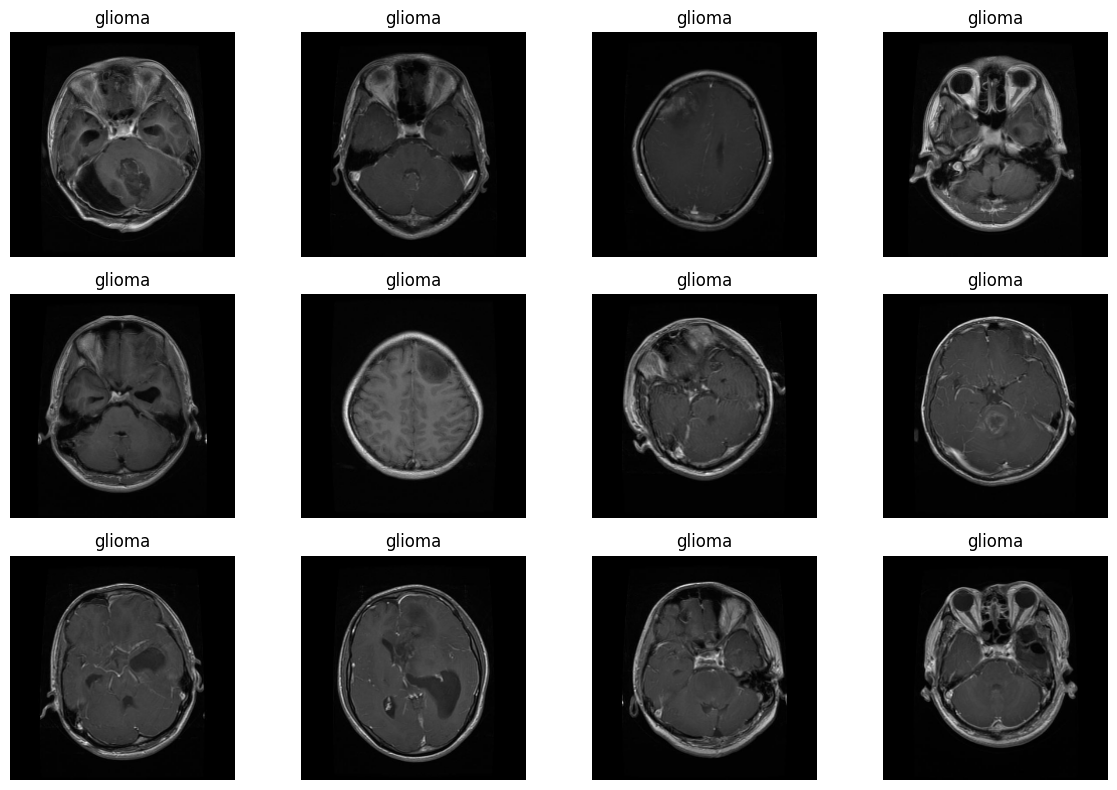

In [8]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X[i])
    plt.title(y[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Encode Class Labels

Convert the categorical class labels into numerical values using `LabelEncoder`. Machine-learning models work with numerical targets, so this step prepares our labels for training.

In [9]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded labels:", np.unique(y_encoded))
print("First 10 labels:", y[:10])
print("First 10 encoded labels:", y_encoded[:10])

Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']
Encoded labels: [0 1 2 3]
First 10 labels: ['glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma'
 'glioma' 'glioma']
First 10 encoded labels: [0 0 0 0 0 0 0 0 0 0]


## Train-Test Split

Split the dataset into training and testing sets. The training set is used to teach the CNN, while the testing set evaluates how well it performs on unseen images.

We use an 80/20 split and `stratify=y_encoded` to preserve approximately the same class proportions in both sets.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Train-Test Split complete!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train count:", len(y_train))
print("y_test count:", len(y_test))

Train-Test Split complete!
X_train shape: (5618, 224, 224, 3)
X_test shape: (1405, 224, 224, 3)
y_train count: 5618
y_test count: 1405


In [11]:
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

def prepare_batch(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_train_part, y_train_part))
    .shuffle(2000)
    .batch(8)
    .map(prepare_batch, num_parallel_calls=1)
    .prefetch(1)
)

val_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_val, y_val))
    .batch(8)
    .map(prepare_batch, num_parallel_calls=1)
    .prefetch(1)
)

## Image Normalization

Normalize pixel values from the range 0–255 to the range 0–1 by dividing by 255.0.

This helps the CNN train more efficiently because the input values have a smaller, consistent scale. We apply the same transformation to both training and testing images.

In [12]:
#X_train = X_train.astype("float32") / 255.0
#X_test = X_test.astype("float32") /255.0

#print("X_train range:", X_train.min(), "to", X_train.max())
#print("X_test range:", X_test.min(), "to", X_test.max())
#print("X_train dtype:", X_train.dtype)
#print("X_test dtype:", X_test.dtype)

## Random Sample Visualization

Display randomly selected MRI images from the training set, including their class labels. This helps us visually inspect the dataset and verify that all four classes are represented.

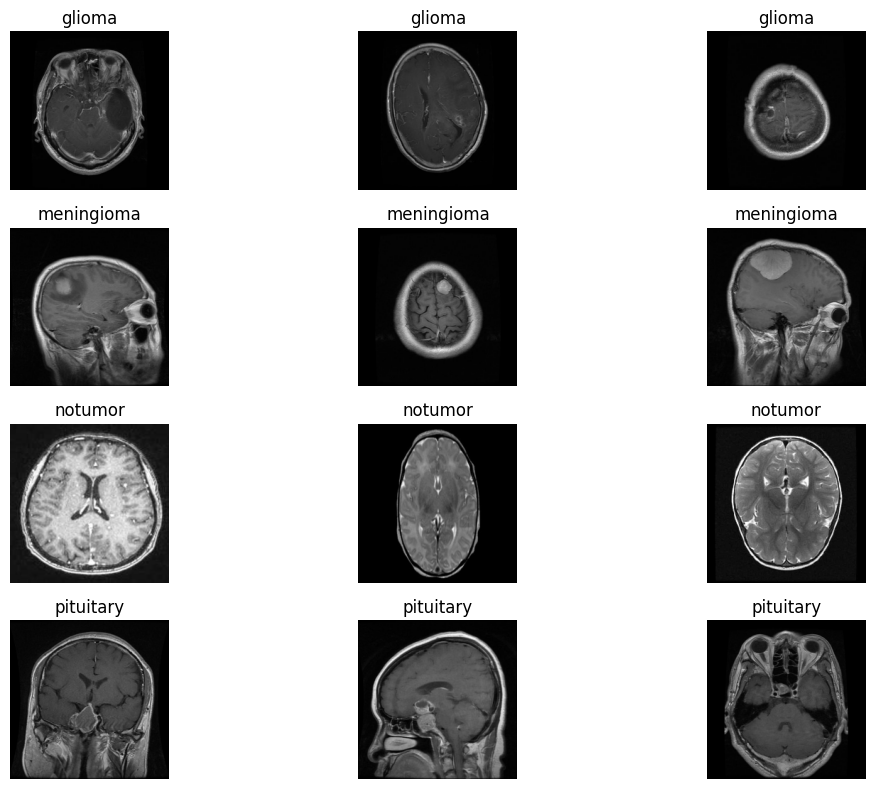

In [13]:
class_names = label_encoder.classes_

plt.figure(figsize=(12, 8))

for class_id, class_name in enumerate(class_names):
    indices = np.where(y_train == class_id)[0]
    random_indices = random.sample(list(indices), 3)

    for j, idx in enumerate(random_indices):
        plt.subplot(4, 3, class_id * 3 + j + 1)
        plt.imshow(X_train[idx])
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

## Training and Testing Class Distribution

Compare the number of images from each class in the training and testing sets. This verifies that stratified splitting preserved the class proportions and helps identify any imbalance that could affect model training.

,Class,Training Images,Testing Images
0,glioma,1297,324
1,meningioma,1316,329
2,notumor,1600,400
3,pituitary,1405,352


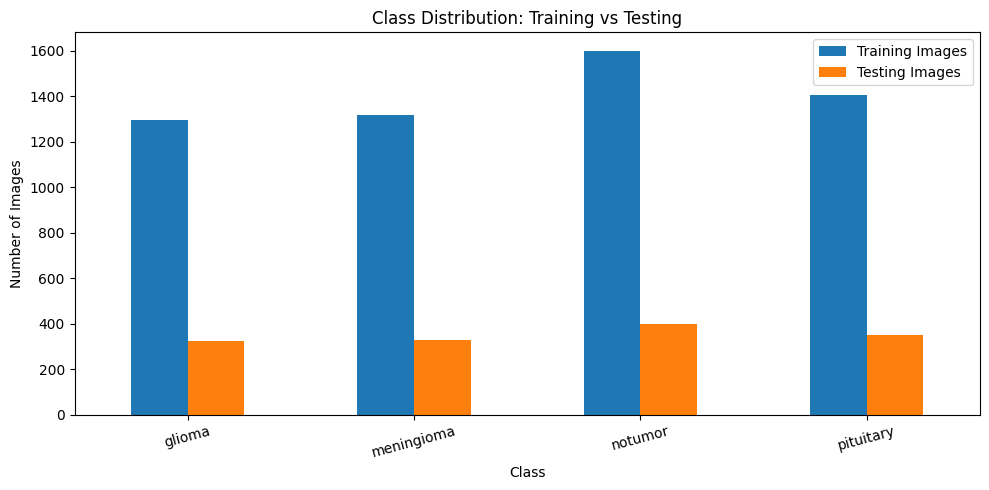

In [14]:
train_counts = Counter(y_train)
test_counts = Counter(y_test)

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Training Images": [train_counts[i] for i in range(len(class_names))],
    "Testing Images": [test_counts[i] for i in range(len(class_names))]
})

display(distribution_df)

distribution_df.set_index("Class").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Class Distribution: Training vs Testing")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## CNN Architecture

Build a Convolutional Neural Network (CNN) using convolution, pooling, dropout, and dense layers.

- **Conv2D:** learns visual features such as edges, shapes, and patterns.
- **MaxPooling2D:** reduces feature-map dimensions while retaining important information.
- **Dropout:** randomly disables some neurons during training to help reduce overfitting.
- **Flatten:** converts feature maps into a one-dimensional vector.
- **Dense:** combines learned features to classify the MRI image.

The input shape is 224 × 224 × 3, and the output contains four class scores.

In [15]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224,224,3)),

    tf.keras.layers.Conv2D(32,(3,3),activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64,(3,3),activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(128,(3,3)),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(4,activation="softmax")

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## Compile the CNN Model

Configure the CNN for training by selecting an optimizer, a loss function, and evaluation metrics.

- **Adam:** updates the model's weights and biases to reduce prediction errors.
- **Sparse Categorical Crossentropy:** measures the difference between predicted probabilities and the correct class labels encoded as integers.
- **Accuracy:** measures the percentage of images classified correctly.

We use sparse categorical crossentropy because our labels are integers (0, 1, 2, and 3), not one-hot encoded vectors.

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")
print("Optimizer:", model.optimizer.name)
print("Loss function:", model.loss)
print("Metrics:", model.metrics_names)

Model compiled successfully!
Optimizer: adam
Loss function: sparse_categorical_crossentropy
Metrics: ['loss', 'compile_metrics']


### Train the CNN Model
Before training, we will configure two callbacks:
- ModelCheckpoint: saves the model whenever its validation loss improves.
- EarlyStopping: stops training if validation loss does not improve for 5 consecutive epochs and restores the best weights.

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / "best_brainscan_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

### Train the moodel

In [18]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[checkpoint, early_stopping],
    shuffle=True
)

Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.2872 - loss: 74.5267
Epoch 1: val_loss improved from None to 1.38477, saving model to /content/best_brainscan_model.keras

Epoch 1: finished saving model to /content/best_brainscan_model.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - accuracy: 0.2830 - loss: 19.4828 - val_accuracy: 0.2900 - val_loss: 1.3848
Epoch 2/20
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.2783 - loss: 1.3848
Epoch 2: val_loss improved from 1.38477 to 1.38344, saving model to /content/best_brainscan_model.keras

Epoch 2: finished saving model to /content/best_brainscan_model.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.2835 - loss: 1.3845 - val_accuracy: 0.2900 - val_loss: 1.3834
Epoch 3/20
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.2842 - loss: 1.3837
Epoch 3: val_loss improved from 1.38344 to 1.38276, saving model to /content/best_brainscan_model.keras

Epoch 3: finished saving model to /content/be

In [19]:
print("X_train dtype:", X_train.dtype)
print("X_train min:", X_train.min())
print("X_train max:", X_train.max())

print("X_test dtype:", X_test.dtype)
print("X_test min:", X_test.min())
print("X_test max:", X_test.max())

X_train dtype: uint8
X_train min: 0
X_train max: 255
X_test dtype: uint8
X_test min: 0
X_test max: 255


## Evaluate the CNN Model

Evaluate the trained CNN on the test dataset to estimate how well it
classifies MRI images it has not seen during training.

We will calculate test loss and accuracy, then compare the predicted
classes with the true labels using a classification report and confusion matrix.

In [20]:
test_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_test, y_test))
    .batch(8)
    .map(prepare_batch, num_parallel_calls=1)
    .prefetch(1)
)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.2847 - loss: 1.3736
Test Loss: 1.3736
Test Accuracy: 28.47%


In [21]:
for images, labels in train_ds.take(1):
    print("Training images:", images.shape)
    print("Training pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))
    print("Training labels:", labels[:10].numpy())

for images, labels in val_ds.take(1):
    print("Validation images:", images.shape)
    print("Validation pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training images: (8, 224, 224, 3)
Training pixel range: 0.0 to 0.9921568632125854
Training labels: [1 3 0 2 0 1 3 1]
Validation images: (8, 224, 224, 3)
Validation pixel range: 0.0 to 1.0
Training batches: 562
Validation batches: 141


In [22]:
tf.keras.backend.clear_session()

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / "brainscan_model_v2.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[checkpoint, early_stopping]
)

Epoch 1/20
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5948 - loss: 0.9449
Epoch 1: val_loss improved from None to 0.48277, saving model to /content/brainscan_model_v2.keras

Epoch 1: finished saving model to /content/brainscan_model_v2.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 29s 38ms/step - accuracy: 0.7043 - loss: 0.7455 - val_accuracy: 0.8132 - val_loss: 0.4828
Epoch 2/20
561/562 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8070 - loss: 0.4878
Epoch 2: val_loss improved from 0.48277 to 0.39915, saving model to /content/brainscan_model_v2.keras

Epoch 2: finished saving model to /content/brainscan_model_v2.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8264 - loss: 0.4425 - val_accuracy: 0.8390 - val_loss: 0.3991
Epoch 3/20
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8660 - loss: 0.3354
Epoch 3: val_loss improved from 0.39915 to 0.25364, saving model to /content/brainscan_model_v2.keras

Epoch 3: finished saving model to /content/brainscan_model_

176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9338 - loss: 0.2099
Test Loss: 0.2099
Test Accuracy: 93.38%
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.84      0.90       324
  meningioma       0.83      0.91      0.87       329
     notumor       0.97      0.98      0.98       400
   pituitary       0.96      0.98      0.97       352

    accuracy                           0.93      1405
   macro avg       0.93      0.93      0.93      1405
weighted avg       0.94      0.93      0.93      1405



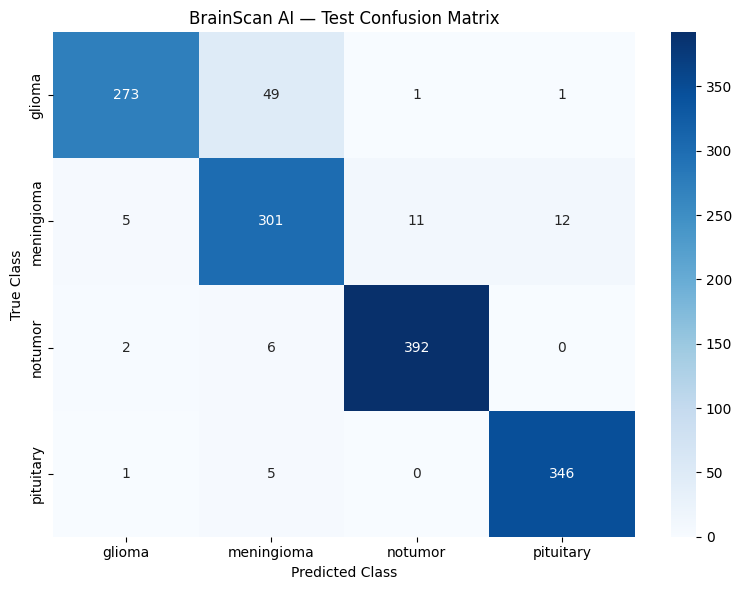

In [ ]:
best_model = tf.keras.models.load_model(
    MODEL_DIR / "brainscan_model_v2.keras"
)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("BrainScan AI — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Training History and Overfitting Analysis

We compare training and validation accuracy and loss across epochs.
A growing gap between training and validation performance can indicate overfitting.

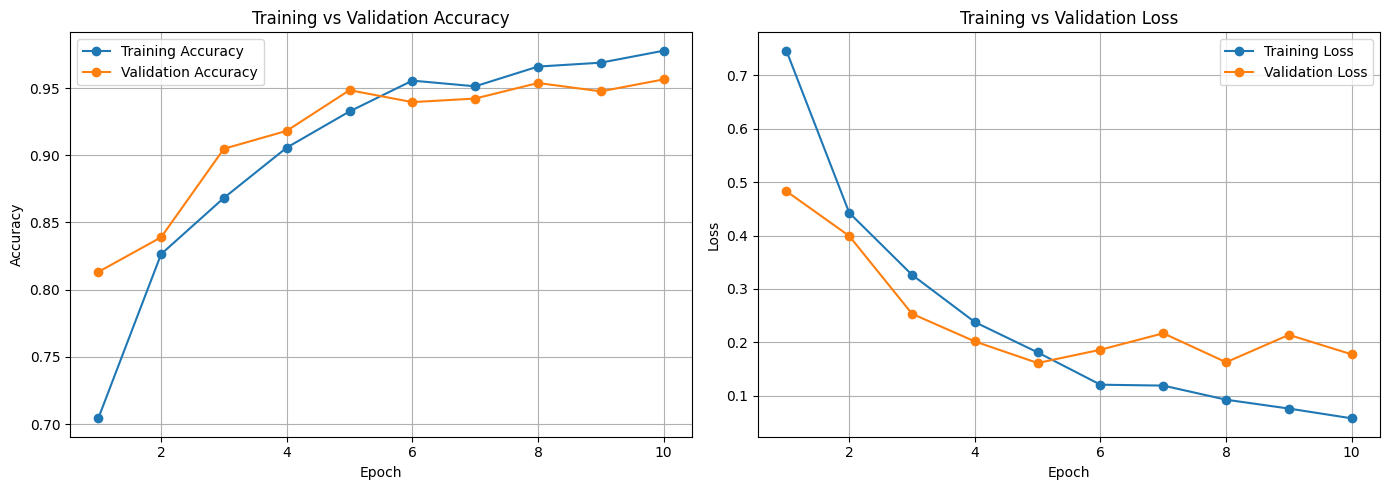

In [25]:
import matplotlib.pyplot as plt

history_data = history.history
epochs = range(1, len(history_data["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history_data["accuracy"], marker="o",
             label="Training Accuracy")
axes[0].plot(epochs, history_data["val_accuracy"], marker="o",
             label="Validation Accuracy")
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(epochs, history_data["loss"], marker="o",
             label="Training Loss")
axes[1].plot(epochs, history_data["val_loss"], marker="o",
             label="Validation Loss")
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Model Evaluation on the Test Set

The test set contains images that were not used to train the model or select the best epoch. We use it to measure how well the trained CNN generalizes to unseen images.

We will calculate the test loss and accuracy, then analyze its predictions using a classification report and confusion matrix.

In [ ]:
# Load the saved best model
best_model = tf.keras.models.load_model(
    MODEL_DIR / "brainscan_model_v2.keras"
)

# Evaluate on the test set
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9338 - loss: 0.2099
Test Loss: 0.2099
Test Accuracy: 93.38%


176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
              precision    recall  f1-score   support

      glioma     0.9715    0.8426    0.9025       324
  meningioma     0.8338    0.9149    0.8725       329
     notumor     0.9703    0.9800    0.9751       400
   pituitary     0.9638    0.9830    0.9733       352

    accuracy                         0.9338      1405
   macro avg     0.9349    0.9301    0.9308      1405
weighted avg     0.9370    0.9338    0.9339      1405



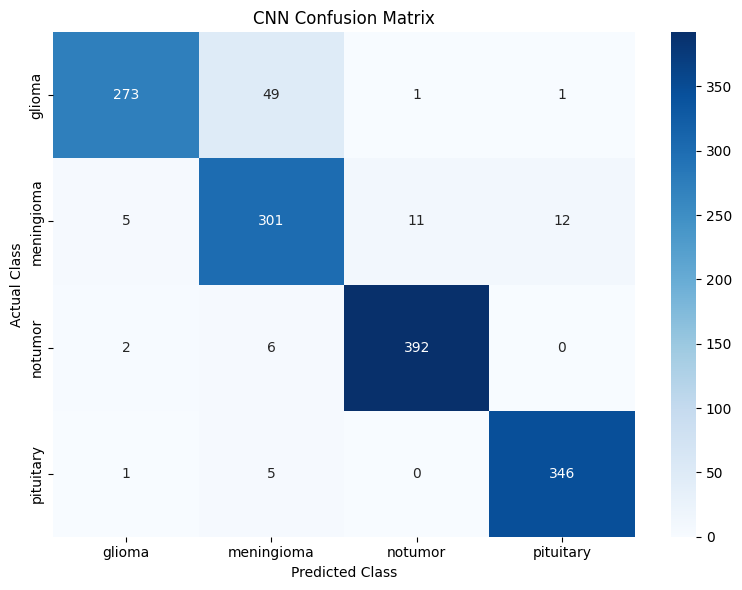

In [27]:
# Get predicted probabilities for each class
y_prob = best_model.predict(test_ds)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Get the actual labels in the same order as test_ds
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])

# Class names in LabelEncoder order
class_names = label_encoder.classes_

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

### Error Analysis

We inspect images that the CNN classified incorrectly. This helps us identify confusing patterns between tumor classes and decide how to improve the model.

Incorrect predictions: 93


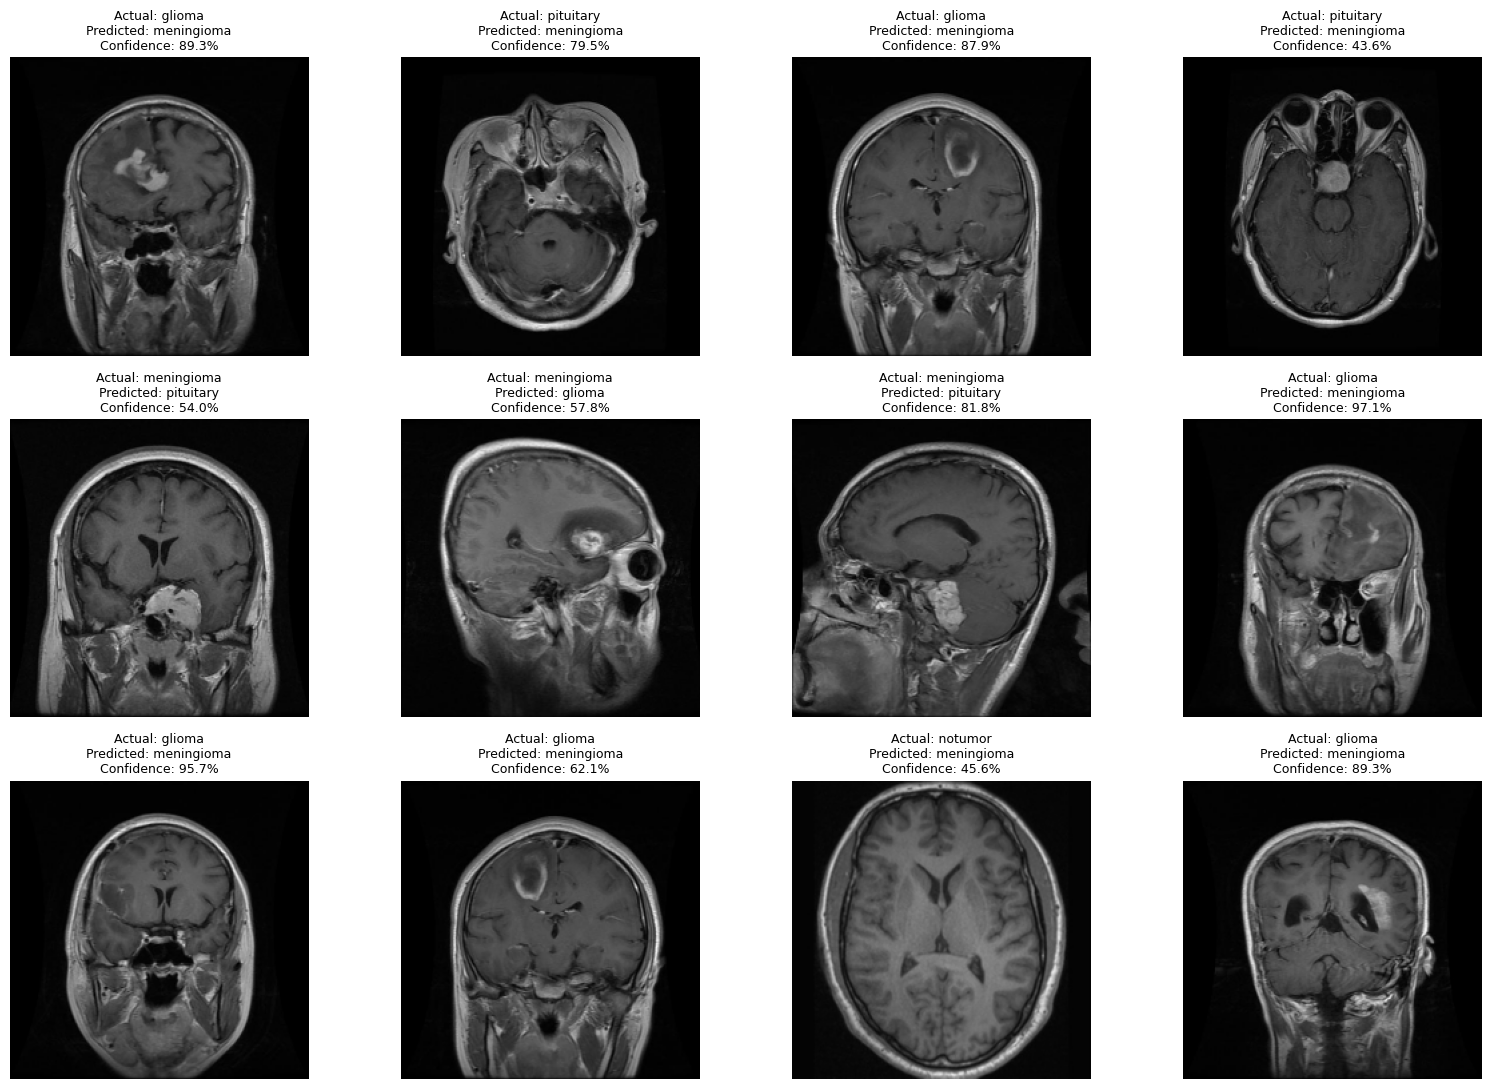

In [28]:
# Find the indices of incorrectly classified images
wrong_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(wrong_indices))

# Display up to 12 misclassified images
n_images = min(12, len(wrong_indices))

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i in range(n_images):
    idx = wrong_indices[i]

    actual = class_names[y_true[idx]]
    predicted = class_names[y_pred[idx]]
    confidence = y_prob[idx].max() * 100

    axes[i].imshow(X_test[idx])
    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=9
    )
    axes[i].axis("off")

for i in range(n_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [29]:
# Show only incorrect predictions
errors_df = pd.DataFrame({
    "Actual": [class_names[i] for i in y_true[wrong_indices]],
    "Predicted": [class_names[i] for i in y_pred[wrong_indices]]
})

error_counts = (
    errors_df
    .value_counts()
    .reset_index(name="Number of Errors")
    .sort_values("Number of Errors", ascending=False)
)

display(error_counts)

,Actual,Predicted,Number of Errors
0,glioma,meningioma,49
1,meningioma,pituitary,12
2,meningioma,notumor,11
3,notumor,meningioma,6
4,pituitary,meningioma,5
5,meningioma,glioma,5
6,notumor,glioma,2
7,glioma,notumor,1
8,glioma,pituitary,1
9,pituitary,glioma,1


## Experiment 2: CNN with Data Augmentation

We add random image transformations to help the CNN learn more robust features and potentially reduce overfitting. We will compare this model with the original CNN.

In [30]:
tf.keras.backend.clear_session()

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
], name="data_augmentation")

model_aug = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(4, activation="softmax")
])

model_aug.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the Model

We use Adam to optimize the weights and sparse categorical cross-entropy because our four classes are represented by integer labels.

In [31]:
model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Configure Callbacks

ModelCheckpoint saves the model with the lowest validation loss. EarlyStopping stops training when validation loss stops improving and restores the best weights.

In [ ]:
checkpoint_aug = tf.keras.callbacks.ModelCheckpoint(
    MODEL_DIR / "brainscan_model_augmented.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_aug = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

### Train the Augmented CNN

Train the model using the existing training and validation datasets. Augmentation is applied during training, not during validation or prediction.

In [33]:
history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[checkpoint_aug, early_stopping_aug]
)

Epoch 1/20
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5168 - loss: 1.1014
Epoch 1: val_loss improved from None to 0.72465, saving model to /content/brainscan_model_augmented.keras

Epoch 1: finished saving model to /content/brainscan_model_augmented.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.6170 - loss: 0.9417 - val_accuracy: 0.7109 - val_loss: 0.7246
Epoch 2/20
561/562 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6942 - loss: 0.7497
Epoch 2: val_loss improved from 0.72465 to 0.51830, saving model to /content/brainscan_model_augmented.keras

Epoch 2: finished saving model to /content/brainscan_model_augmented.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 22s 39ms/step - accuracy: 0.7154 - loss: 0.7075 - val_accuracy: 0.7696 - val_loss: 0.5183
Epoch 3/20
561/562 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7478 - loss: 0.6252
Epoch 3: val_loss did not improve from 0.51830
562/562 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.7550 - loss: 0.6064 - val_accu

### Visualize Training Performance

Plot accuracy and loss to observe learning progress and possible overfitting.

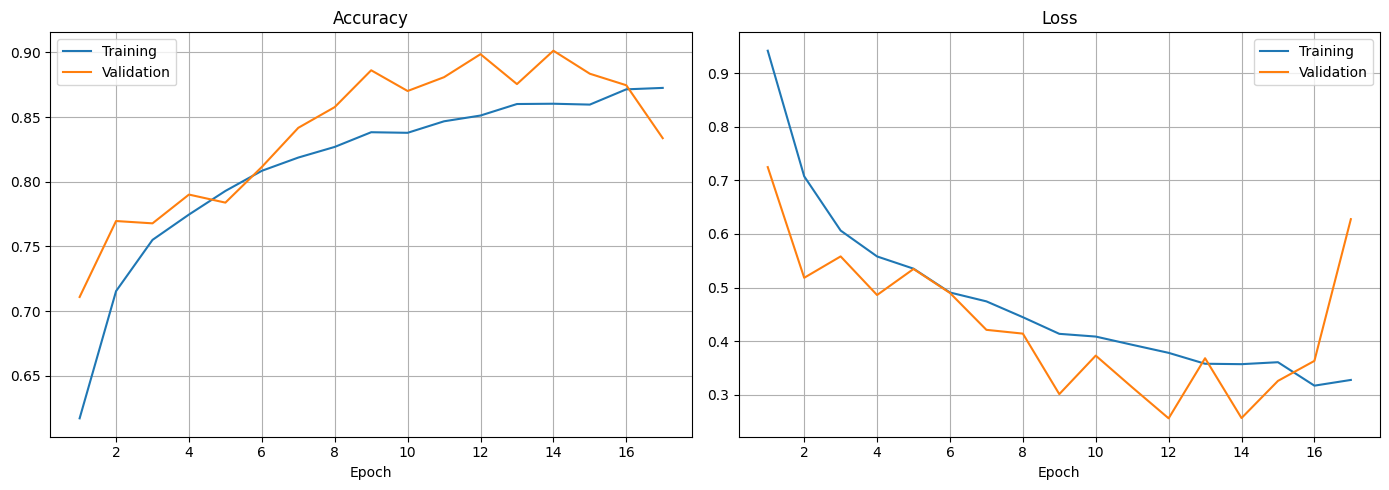

In [34]:
epochs = range(1, len(history_aug.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history_aug.history["accuracy"], label="Training")
axes[0].plot(epochs, history_aug.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history_aug.history["loss"], label="Training")
axes[1].plot(epochs, history_aug.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Evaluate the Augmented CNN

Evaluate the best saved model on the test set to measure its performance on unseen images.

In [ ]:
best_model_aug = tf.keras.models.load_model(
    MODEL_DIR / "brainscan_model_augmented.keras"
)

test_loss_aug, test_accuracy_aug = best_model_aug.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss_aug:.4f}")
print(f"Test Accuracy: {test_accuracy_aug:.2%}")

176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9039 - loss: 0.2770
Test Loss: 0.2770
Test Accuracy: 90.39%


### Classification Report and Confusion Matrix

Analyze precision, recall, F1-score, and classification errors for each class.

176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
              precision    recall  f1-score   support

      glioma     0.9180    0.8642    0.8903       324
  meningioma     0.8307    0.7903    0.8100       329
     notumor     0.9490    0.9775    0.9631       400
   pituitary     0.9040    0.9631    0.9326       352

    accuracy                         0.9039      1405
   macro avg     0.9004    0.8988    0.8990      1405
weighted avg     0.9029    0.9039    0.9028      1405



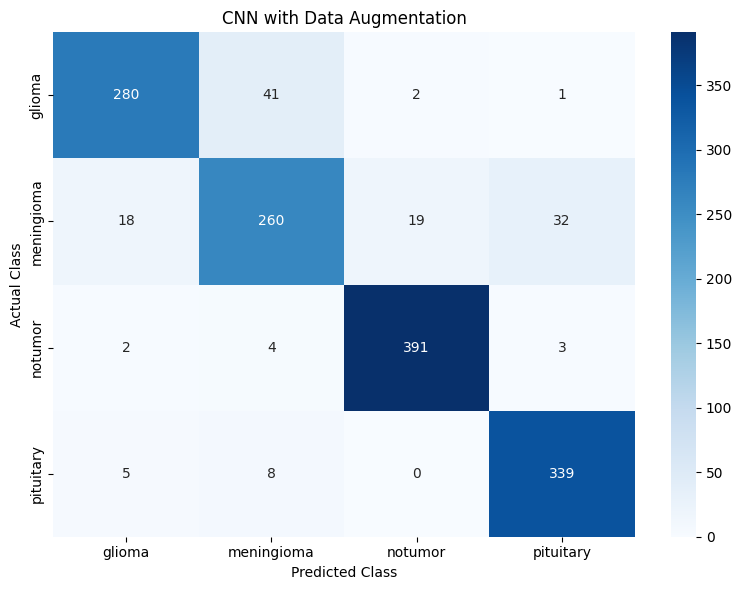

In [36]:
y_prob_aug = best_model_aug.predict(test_ds)
y_pred_aug = np.argmax(y_prob_aug, axis=1)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

class_names = label_encoder.classes_

print(classification_report(
    y_true,
    y_pred_aug,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4
))

cm_aug = confusion_matrix(y_true, y_pred_aug)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_aug,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN with Data Augmentation")
plt.tight_layout()
plt.show()

### Compare Both Models

Compare the augmented CNN with the original baseline. Accuracy and loss are useful, but class-level recall and confusion patterns also matter.

In [37]:
comparison_df = pd.DataFrame({
    "Model": ["Original CNN", "CNN with Augmentation"],
    "Test Accuracy": [0.9281, test_accuracy_aug],
    "Test Loss": [0.2190, test_loss_aug]
})

display(comparison_df.style.format({
    "Test Accuracy": "{:.2%}",
    "Test Loss": "{:.4f}"
}))

,Model,Test Accuracy,Test Loss
0,Original CNN,92.81%,0.2190
1,CNN with Augmentation,90.39%,0.2770


### Training and Validation Accuracy

Training accuracy measures how well the model predicts the images used for learning. Validation accuracy measures how well it predicts separate images that it does not train on.

Comparing these curves helps us understand how well the model learns and generalizes to unseen images.

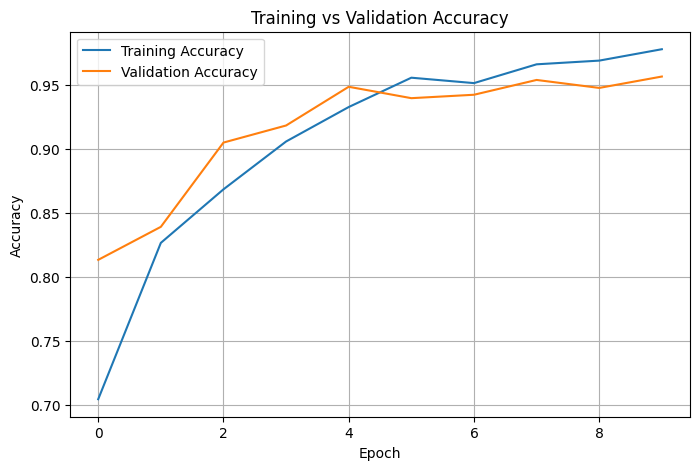

In [38]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Training and Validation Loss

Loss measures how far the model's predictions are from the correct labels. Lower loss is generally better.

Comparing training loss with validation loss helps us detect possible overfitting and identify when further training may no longer improve the model.

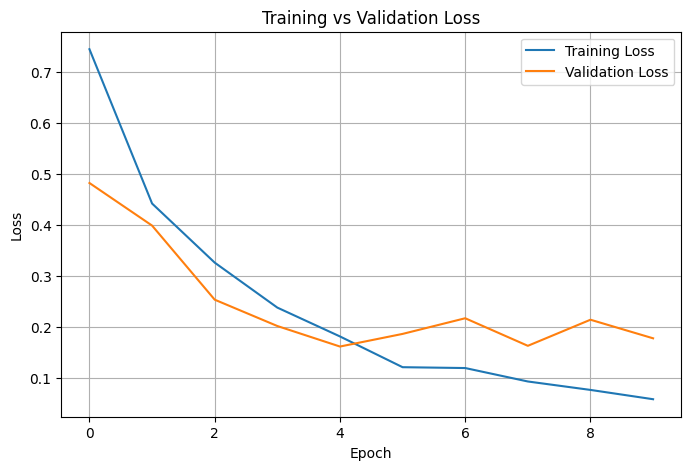

In [39]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### Confusion Matrix

We use the test dataset to compare the model's predicted classes with the actual labels. The confusion matrix helps identify which tumor classes are most frequently confused.

The test dataset is used for final evaluation, not for updating the model's weights.

In [40]:
# Predict the test images

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Predictions shape:", y_pred.shape)
print("Actual labels shape:", y_test.shape)

176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step
Predictions shape: (1405,)
Actual labels shape: (1405,)


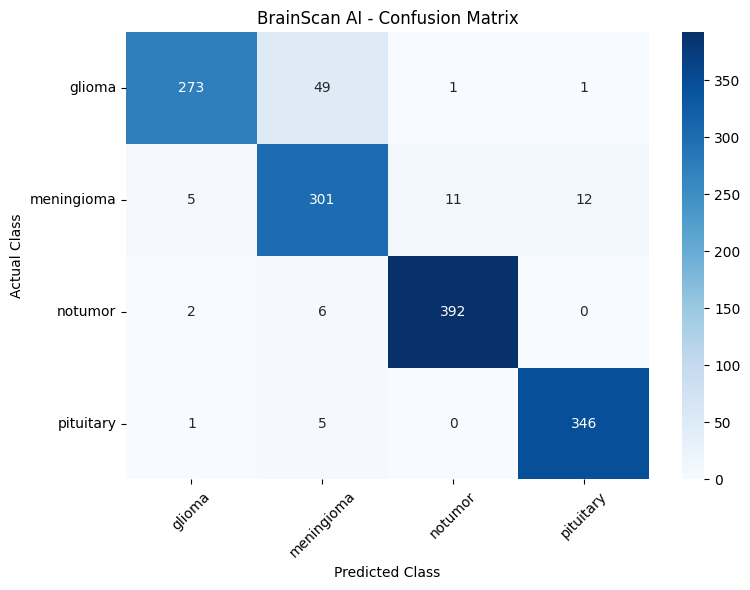

In [41]:
# Build and display the confusion matrix

class_names = label_encoder.classes_

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("BrainScan AI - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Classification Report

The classification report evaluates the model for each class using precision, recall, and F1-score. These metrics help us understand which tumor classes the model recognizes well and which need improvement.

In [42]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

      glioma       0.97      0.84      0.90       324
  meningioma       0.83      0.91      0.87       329
     notumor       0.97      0.98      0.98       400
   pituitary       0.96      0.98      0.97       352

    accuracy                           0.93      1405
   macro avg       0.93      0.93      0.93      1405
weighted avg       0.94      0.93      0.93      1405



### Correct Predictions
Display MRI images correctly classified by the CNN.

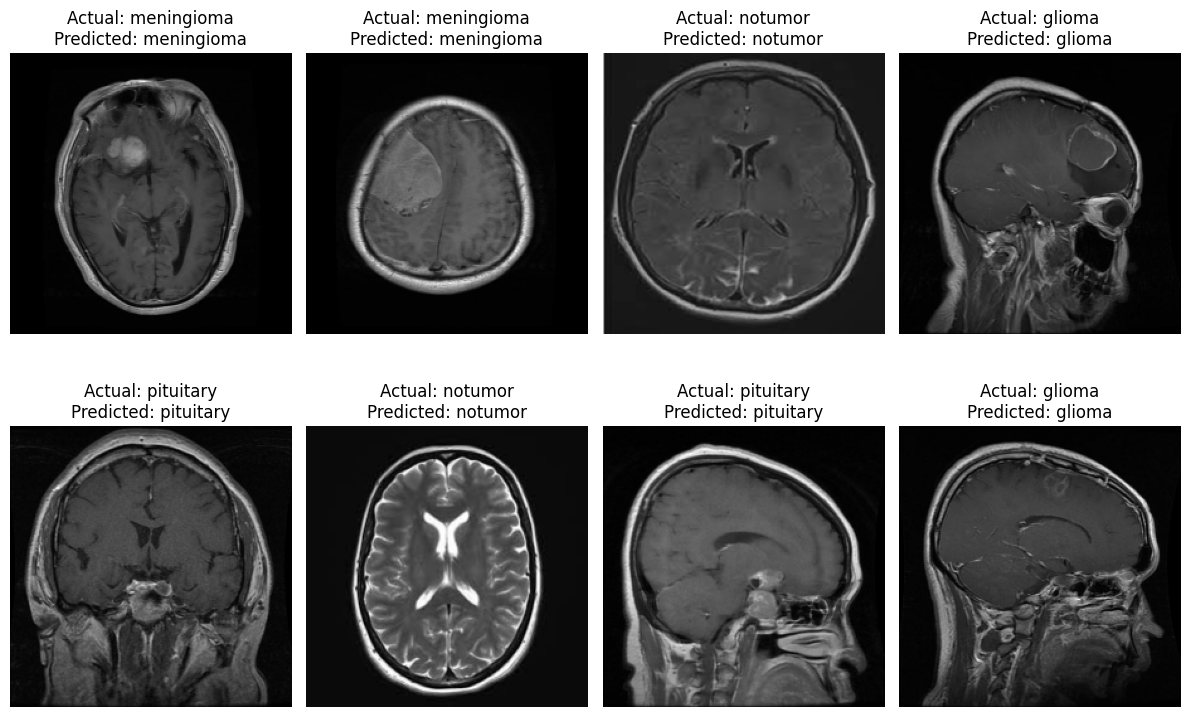

Correct predictions: 1312


In [43]:
# Find correctly classified images
correct_indices = np.where(y_pred == y_test)[0]

plt.figure(figsize=(12, 8))

for i, idx in enumerate(correct_indices[:8]):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_test[idx])

    actual_class = label_encoder.inverse_transform([y_test[idx]])[0]
    predicted_class = label_encoder.inverse_transform([y_pred[idx]])[0]

    plt.title(f"Actual: {actual_class}\nPredicted: {predicted_class}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Correct predictions:", len(correct_indices))

### Incorrect Predictions
Display MRI images misclassified by the CNN.

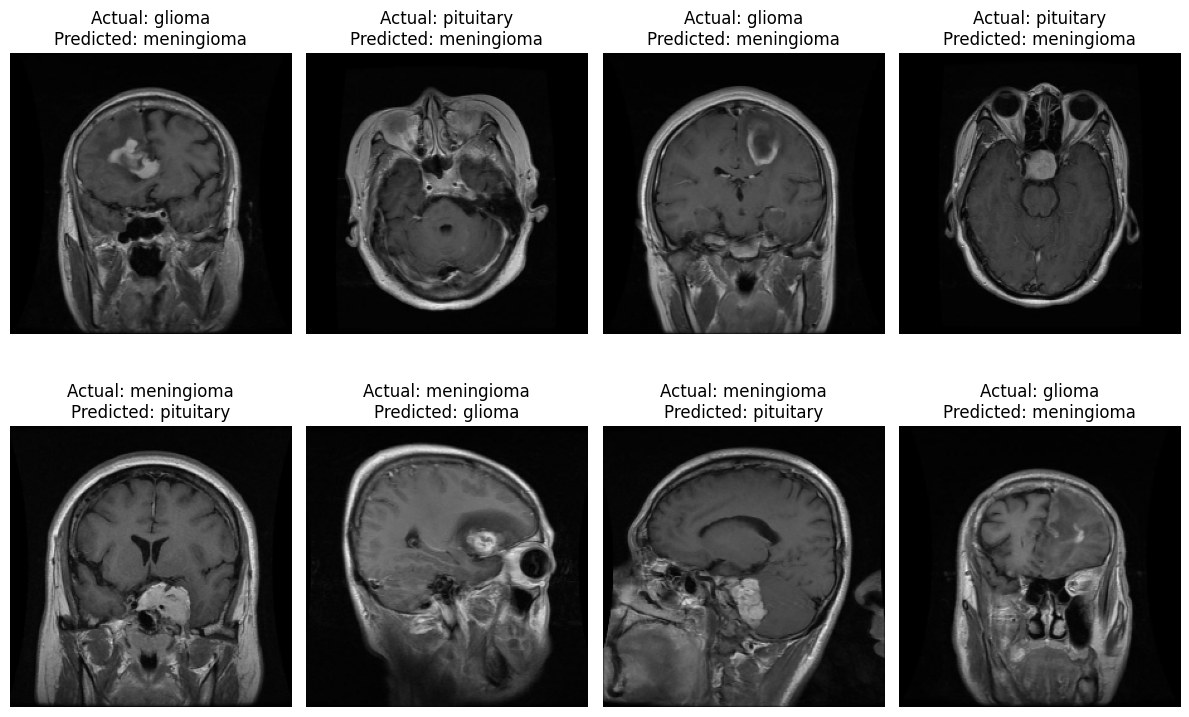

Incorrect predictions: 93


In [44]:
# Find incorrectly classified images
wrong_indices = np.where(y_pred != y_test)[0]

plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:8]):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_test[idx])

    actual_class = label_encoder.inverse_transform([y_test[idx]])[0]
    predicted_class = label_encoder.inverse_transform([y_pred[idx]])[0]

    plt.title(f"Actual: {actual_class}\nPredicted: {predicted_class}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Incorrect predictions:", len(wrong_indices))

### Predict a New MRI Image
Load an MRI image and predict its class and confidence.

In [48]:
def predict_image(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))
    image = image.astype(np.float32) / 255.0
    image = np.expand_dims(image, axis=0)

    probabilities = model.predict(image, verbose=0)[0]
    predicted_idx = np.argmax(probabilities)

    predicted_class = label_encoder.inverse_transform(
        [predicted_idx]
    )[0]

    print("Predicted class:", predicted_class)
    print(f"Confidence: {probabilities[predicted_idx] * 100:.2f}%")

    plt.imshow(image[0])
    plt.title(predicted_class)
    plt.axis("off")
    plt.show()

Predicted class: glioma
Confidence: 99.67%


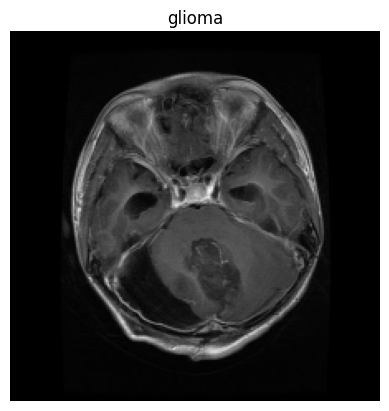

In [ ]:
image_path = DATA_DIR / "glioma" / "Te-glTr_0000.jpg"
predict_image(image_path)

### Save the Model
Save the trained CNN for later use in the application.

In [ ]:
model.save(MODEL_DIR / "brainscan_model.keras")

print("Model saved successfully!")

Model saved successfully!
